In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import comb

from src.models.autoregression.autoregression_model import get_ar_coeffs, verify_moment_conditions, simulate_ar, exact_theoretical_std

ALGEBRAIC DIAGNOSTIC: MOMENT CONDITIONS ON ECHO COEFFICIENTS (phi_k)
m   | phi coefficients   | Sum(phi)=1?  | Sum(k*phi)=0?  | Sum(k^2*phi)=0?  | Sum(k^3*phi)=0?
------------------------------------------------------------------------------
0   | []                 | 0.0          | 0.0            | 0.0              | 0.0           
1   | [1]                | 1.0          | 1.0            | 1.0              | 1.0           
2   | [2, -1]            | 1.0          | 0.0            | -2.0             | -6.0          
3   | [3, -3, 1]         | 1.0          | 0.0            | 0.0              | 6.0           



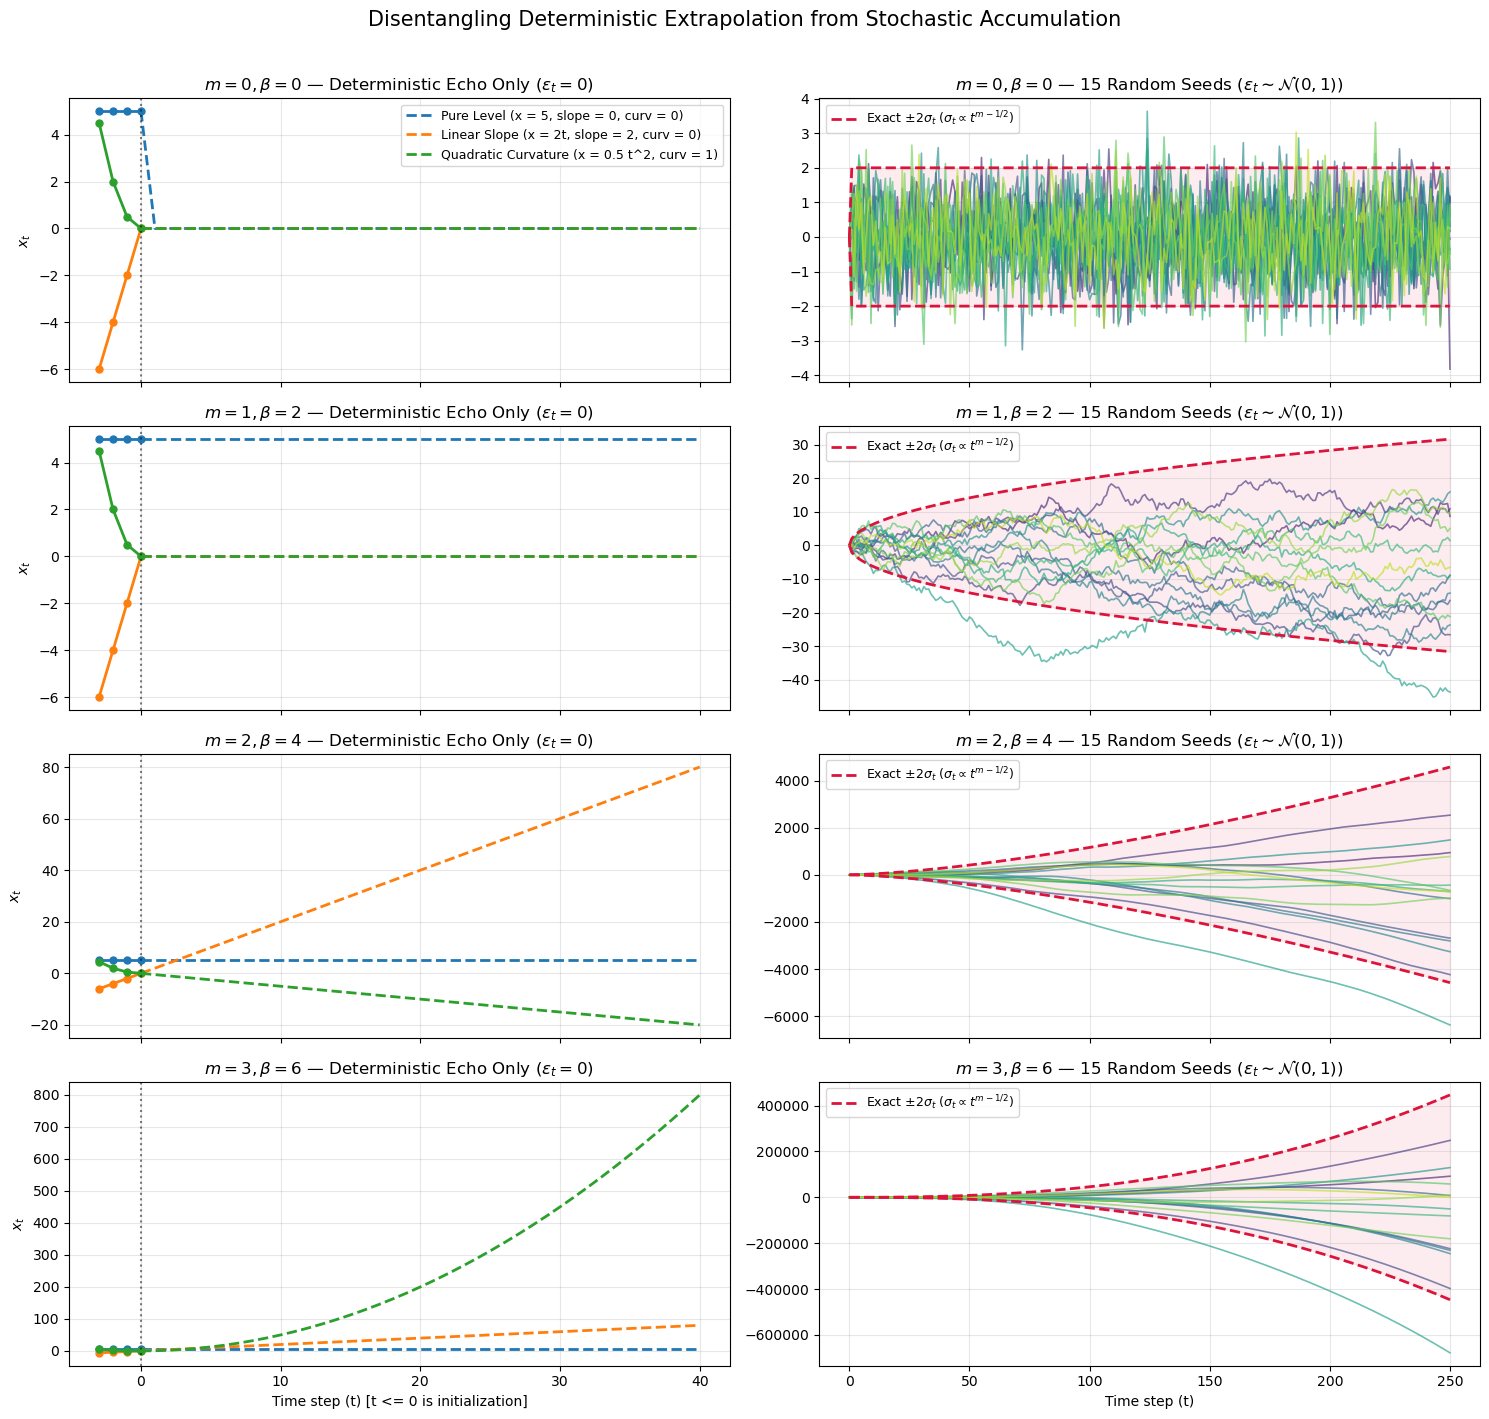

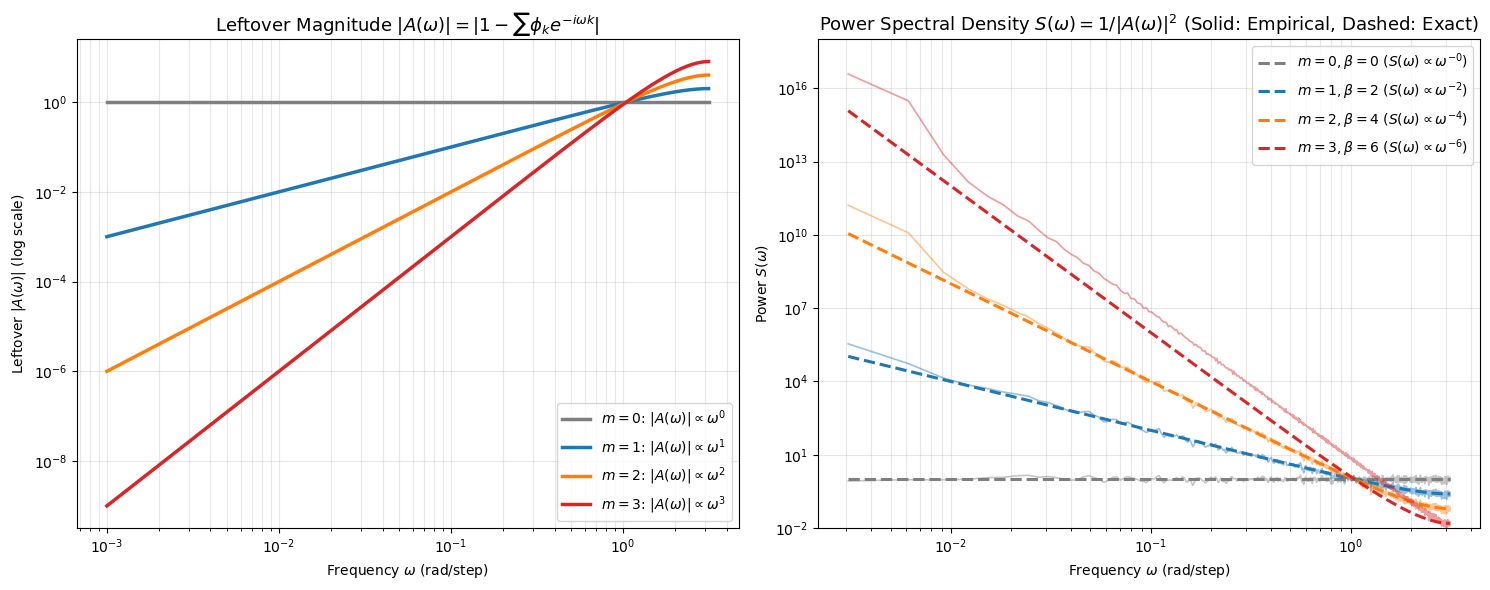

In [2]:

# Run algebraic check in console
verify_moment_conditions(max_m=3)

# =====================================================================
# 2. FIGURE 1: DETERMINISTIC EXTRAPOLATION vs. STOCHASTIC ENSEMBLE
# =====================================================================

n_steps_det = 40    # Shorter horizon to clearly see polynomial extrapolation
n_steps_stoch = 250 # Horizon for stochastic ensemble
n_seeds = 15        # Number of independent random seeds per model

# Initial histories of length 4 (t = -3, -2, -1, 0) to clearly define
# level, slope (1st diff), and curvature (2nd diff) at t = 0:
t_init = np.array([-3, -2, -1, 0], dtype=float)
initializations = {
    "Pure Level (x = 5, slope = 0, curv = 0)": 5.0 + 0.0 * t_init,
    "Linear Slope (x = 2t, slope = 2, curv = 0)": 2.0 * t_init,
    "Quadratic Curvature (x = 0.5 t^2, curv = 1)": 0.5 * (t_init ** 2)
}

fig1, axes1 = plt.subplots(4, 2, figsize=(15, 14), sharex="col")
colors = ["tab:blue", "tab:orange", "tab:green"]

for m in range(4):
    phi = get_ar_coeffs(m)
    beta = 2 * m
    
    # --- LEFT COLUMN: Deterministic Extrapolation (No Kicks, e_t = 0) ---
    ax_det = axes1[m, 0]
    n_init = len(t_init)
    t_full_det = np.arange(-n_init + 1, n_steps_det + 1)
    
    for (init_name, init_vals), col in zip(initializations.items(), colors):
        trace_det = simulate_ar(phi, n_steps_det, init_vals, noise_scale=0.0)
        
        # Plot initialization points (same explicit color!)
        ax_det.plot(t_full_det[:n_init], trace_det[:n_init],
                    marker="o", markersize=5, color=col, linestyle="-", linewidth=2)
        # Plot extrapolated future (same explicit color!)
        ax_det.plot(t_full_det[n_init - 1:], trace_det[n_init - 1:],
                    color=col, linestyle="--", linewidth=2, label=init_name)
        
    ax_det.axvline(0, color="black", linestyle=":", alpha=0.5)
    ax_det.set_title(rf"$m={m}, \beta={beta}$ — Deterministic Echo Only ($\epsilon_t = 0$)", fontsize=12)
    ax_det.set_ylabel(r"$x_t$")
    ax_det.grid(True, alpha=0.3)
    if m == 0:
        ax_det.legend(loc="upper right", fontsize=9)

    # --- RIGHT COLUMN: Stochastic Ensemble (15 Random Seeds + +/- 2 SD Envelope) ---
    ax_stoch = axes1[m, 1]
    init_zero = np.zeros(n_init)
    t_stoch = np.arange(0, n_steps_stoch + 1)
    
    cmap = plt.cm.viridis(np.linspace(0.1, 0.9, n_seeds))
    for s in range(n_seeds):
        rng = np.random.default_rng(seed=1000 + s)
        trace_s = simulate_ar(phi, n_steps_stoch, init_zero, noise_scale=1.0, rng=rng)
        # Slice from the last init point (t=0) onward
        ax_stoch.plot(t_stoch, trace_s[n_init - 1:], color=cmap[s], alpha=0.65, linewidth=1.2)
        
    # Overlay exact theoretical +/- 2 SD envelope
    std_t = np.concatenate([[0.0], exact_theoretical_std(m, n_steps_stoch, noise_scale=1.0)])
    ax_stoch.plot(t_stoch, 2.0 * std_t, color="crimson", linestyle="--", linewidth=2,
                  label=r"Exact $\pm 2\sigma_t$ ($\sigma_t \propto t^{m - 1/2}$)")
    ax_stoch.plot(t_stoch, -2.0 * std_t, color="crimson", linestyle="--", linewidth=2)
    ax_stoch.fill_between(t_stoch, -2.0 * std_t, 2.0 * std_t, color="crimson", alpha=0.08)
    
    ax_stoch.set_title(rf"$m={m}, \beta={beta}$ — {n_seeds} Random Seeds ($\epsilon_t \sim \mathcal{{N}}(0,1)$)", fontsize=12)
    ax_stoch.grid(True, alpha=0.3)
    ax_stoch.legend(loc="upper left", fontsize=9)

axes1[-1, 0].set_xlabel("Time step (t) [t <= 0 is initialization]")
axes1[-1, 1].set_xlabel("Time step (t)")
fig1.suptitle("Disentangling Deterministic Extrapolation from Stochastic Accumulation", fontsize=15, y=1.01)
fig1.tight_layout()
plt.show()

# =====================================================================
# 3. FIGURE 2: FREQUENCY DOMAIN & LEFTOVER DIAGNOSTICS
# =====================================================================

fig2, (ax_leftover, ax_psd) = plt.subplots(1, 2, figsize=(15, 6))

# Frequencies w in (0, pi]
w = np.logspace(-3, np.log10(np.pi), 500)
model_colors = ["tab:gray", "tab:blue", "tab:orange", "tab:red"]

# Simulation parameters for empirical PSD verification
N_fft = 2048
n_psd_seeds = 40
freqs_fft = 2.0 * np.pi * np.fft.rfftfreq(N_fft)[1:] # Exclude w = 0

for m, col in zip(range(4), model_colors):
    phi = get_ar_coeffs(m)
    beta = 2 * m
    
    # 1. Theoretical Leftover |A(w)| = |1 - sum_{k=1}^m phi_k e^{-i w k}|
    if m == 0:
        A_w = np.ones_like(w, dtype=complex)
    else:
        k = np.arange(1, m + 1)[:, None]
        A_w = 1.0 - np.sum(phi[:, None] * np.exp(-1j * k * w[None, :]), axis=0)
    leftover_mag = np.abs(A_w)
    
    ax_leftover.loglog(w, leftover_mag, color=col, linewidth=2.5,
                       label=rf"$m={m}$: $|A(\omega)| \propto \omega^{m}$")
    
    # 2. Empirical vs. Theoretical PSD S(w) = 1 / |A(w)|^2
    # Wait: to compute clean FFT without boundary jump artifacts on non-stationary
    # I(m) traces, we apply the theoretical inverse relationship or measure
    # the periodogram of the stationary m-th difference divided by |1 - e^{-iw}|^{2m},
    # OR apply a Hann window to reduce spectral leakage on raw traces.
    # Here we compute the raw periodogram on length-N_fft traces and compare!
    psd_accum = np.zeros_like(freqs_fft)
    init_z = np.zeros(max(1, m))
    for s in range(n_psd_seeds):
        rng = np.random.default_rng(seed=5000 + s)
        x_sim = simulate_ar(phi, N_fft, init_z, noise_scale=1.0, rng=rng)[len(init_z):]
        # Compute standard periodogram (unwindowed); note that for beta >= 4,
        # finite-sample endpoint jumps cause w^-2 leakage at high frequencies unless detrended/windowed.
        # Applying a Blackman-Harris window suppresses endpoint jump leakage:
        win = np.blackman(N_fft)
        win /= np.sqrt(np.mean(win ** 2))
        X_f = np.fft.rfft(x_sim * win)[1:]
        psd_accum += (np.abs(X_f) ** 2) / N_fft
        
    psd_emp = psd_accum / n_psd_seeds
    psd_theo = 1.0 / (np.abs(2.0 * np.sin(freqs_fft / 2.0)) ** (2 * m))
    
    ax_psd.loglog(freqs_fft, psd_emp, color=col, alpha=0.45, linewidth=1.2)
    ax_psd.loglog(freqs_fft, psd_theo, color=col, linestyle="--", linewidth=2.2,
                  label=rf"$m={m}, \beta={beta}$ ($S(\omega) \propto \omega^{{-{beta}}}$)")

ax_leftover.set_title(r"Leftover Magnitude $|A(\omega)| = |1 - \sum \phi_k e^{-i\omega k}|$", fontsize=13)
ax_leftover.set_xlabel(r"Frequency $\omega$ (rad/step)")
ax_leftover.set_ylabel(r"Leftover $|A(\omega)|$ (log scale)")
ax_leftover.grid(True, which="both", alpha=0.3)
ax_leftover.legend(fontsize=10)

ax_psd.set_title(r"Power Spectral Density $S(\omega) = 1 / |A(\omega)|^2$ (Solid: Empirical, Dashed: Exact)", fontsize=13)
ax_psd.set_xlabel(r"Frequency $\omega$ (rad/step)")
ax_psd.set_ylabel(r"Power $S(\omega)$")
ax_psd.set_ylim(1e-2, 1e18)
ax_psd.grid(True, which="both", alpha=0.3)
ax_psd.legend(fontsize=10)

fig2.tight_layout()
plt.show()